<a href="https://colab.research.google.com/github/sarangmarath/Driver-Behavior-and-Driving-Risk-Recognition/blob/main/asaaasasasas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%cd /content
!git clone https://github.com/sarangmarath/Driver-Behavior-and-Driving-Risk-Recognition.git
%cd /content/Driver-Behavior-and-Driving-Risk-Recognition
!ls

/content
Cloning into 'Driver-Behavior-and-Driving-Risk-Recognition'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 36 (delta 8), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 4.71 MiB | 13.21 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/Driver-Behavior-and-Driving-Risk-Recognition
 notebooks   plots   README.md	'train_models_(1).ipynb'   uah_features.csv


In [2]:
# CELL 2: Imports and Configuration

import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    make_scorer,
    precision_score,
    recall_score
)
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier
)
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42

CLASS_LABELS = [0, 1, 2, 3]

LABEL_NAMES = [
    "No recorded event",
    "Braking",
    "Turning",
    "Acceleration"
]

REPO_ROOT = Path.cwd()

DATA_PATH = REPO_ROOT / "uah_features.csv"

RESULTS_DIR = REPO_ROOT / "results"
PLOTS_DIR = REPO_ROOT / "plots"
MODELS_DIR = REPO_ROOT / "models"

for directory in [RESULTS_DIR, PLOTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Fixed-label macro F1 scorer
MACRO_F1_SCORER = make_scorer(
    f1_score,
    labels=CLASS_LABELS,
    average="macro",
    zero_division=0
)

print("Configuration initialized.")
print("Dataset:", DATA_PATH)
print("Results:", RESULTS_DIR)

Configuration initialized.
Dataset: /content/Driver-Behavior-and-Driving-Risk-Recognition/uah_features.csv
Results: /content/Driver-Behavior-and-Driving-Risk-Recognition/results


In [3]:
# CELL 3: Load and Validate Dataset

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

print("========== DATASET INSPECTION ==========")

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nAvailable columns:")
print(df.columns.tolist())

META_COLUMNS = [
    "trip", "driver", "behavior",
    "road", "label", "label_name", "active"
]

# Correct class name
if "label_name" in df.columns:
    df["label_name"] = df["label_name"].replace({
        "Normal": "No recorded event",
        "No recorderd event": "No recorded event"
    })

# Active flag
ACTIVE_VERIFIED = False

if "active" in df.columns:
    initial_rows = len(df)

    df = df[df["active"] == 1].copy()

    print(
        f"Removed {initial_rows - len(df)} inactive windows."
    )

    ACTIVE_VERIFIED = True

else:
    print(
        "WARNING: Active flag is unavailable. "
        "The 50 km/h activation condition cannot be verified."
    )

# Identify acceleration columns
lat_mean_col = next(
    (c for c in ["ay_kf_mean", "ay_mean"] if c in df.columns),
    None
)

lon_mean_col = next(
    (c for c in ["az_kf_mean", "az_mean"] if c in df.columns),
    None
)

lat_std_col = next(
    (c for c in ["ay_kf_std", "ay_std"] if c in df.columns),
    None
)

lon_std_col = next(
    (c for c in ["az_kf_std", "az_std"] if c in df.columns),
    None
)

print("\nSensor mapping:")
print("Lateral:", lat_mean_col)
print("Longitudinal:", lon_mean_col)

assert lat_mean_col is not None, "Lateral acceleration mean missing."
assert lon_mean_col is not None, "Longitudinal acceleration mean missing."

# Validate metadata
required = ["trip", "driver", "label"]

missing = [c for c in required if c not in df.columns]

assert not missing, f"Missing required columns: {missing}"

df["label"] = df["label"].astype(int)

assert set(df["label"].unique()).issubset(
    set(CLASS_LABELS)
), "Unexpected labels found."

assert set(df["label"].unique()) == set(CLASS_LABELS), (
    "One or more event classes are absent from the dataset."
)

# Identify numeric features
FEATURE_COLUMNS = [
    c for c in df.columns
    if c not in META_COLUMNS
    and pd.api.types.is_numeric_dtype(df[c])
]

# Exclude non-feature identifiers if present
NON_FEATURE_COLUMNS = [
    "timestamp", "time", "window_start",
    "window_end", "start_time", "end_time",
    "sample_count", "duration"
]

FEATURE_COLUMNS = [
    c for c in FEATURE_COLUMNS
    if c not in NON_FEATURE_COLUMNS
]

X = df[FEATURE_COLUMNS].copy()
y = df["label"].copy()

groups = df["trip"].astype(str)
driver_groups = df["driver"].astype(str)

assert X.shape[1] == 29, (
    f"Expected 29 original features, found {X.shape[1]}. "
    "Inspect the feature CSV schema before proceeding."
)

assert X.replace([np.inf, -np.inf], np.nan).notna().all().all(), (
    "Missing or infinite feature values found."
)

print("\n========== VALIDATION ==========")
print("Rows:", len(df))
print("Original features:", len(FEATURE_COLUMNS))
print("Trips:", groups.nunique())
print("Drivers:", driver_groups.nunique())
print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nDataset validation completed.")

========== DATASET INSPECTION ==========
Rows: 31055
Columns: 35

Available columns:
['trip', 'driver', 'behavior', 'road', 'label', 'label_name', 'ax_kf_mean', 'ax_kf_std', 'ax_kf_min', 'ax_kf_max', 'ay_kf_mean', 'ay_kf_std', 'ay_kf_min', 'ay_kf_max', 'az_kf_mean', 'az_kf_std', 'az_kf_min', 'az_kf_max', 'roll_mean', 'roll_std', 'roll_min', 'roll_max', 'pitch_mean', 'pitch_std', 'pitch_min', 'pitch_max', 'yaw_mean', 'yaw_std', 'yaw_min', 'yaw_max', 'speed_mean', 'speed_std', 'speed_min', 'speed_max', 'acc_xy_mag_std']

Sensor mapping:
Lateral: ay_kf_mean
Longitudinal: az_kf_mean

========== VALIDATION ==========
Rows: 31055
Original features: 29
Trips: 40
Drivers: 6

Class distribution:
label
0    29860
1      520
2      366
3      309
Name: count, dtype: int64

Dataset validation completed.


In [4]:
# CELL 4: Feature Engineering and Group-Aware Split

df = df.copy()

# -------------------------------------------------
# 1. Identify available window statistics
# -------------------------------------------------

lat_mean = lat_mean_col
lon_mean = lon_mean_col

lat_std = lat_std_col
lon_std = lon_std_col

lat_max = next(
    (c for c in ["ay_kf_max", "ay_max"] if c in df.columns),
    None
)

lat_min = next(
    (c for c in ["ay_kf_min", "ay_min"] if c in df.columns),
    None
)

lon_max = next(
    (c for c in ["az_kf_max", "az_max"] if c in df.columns),
    None
)

lon_min = next(
    (c for c in ["az_kf_min", "az_min"] if c in df.columns),
    None
)

# -------------------------------------------------
# 2. Range features
# -------------------------------------------------

if lat_max and lat_min:
    df["ay_range"] = df[lat_max] - df[lat_min]

if lon_max and lon_min:
    df["az_range"] = df[lon_max] - df[lon_min]

# -------------------------------------------------
# 3. RMS estimates from window moments
# -------------------------------------------------
# Assumption: stored standard deviations use
# population standard deviation (ddof=0).
# These are estimates, not raw-sample RMS.

if lat_std:
    df["ay_rms_moment_estimate"] = np.sqrt(
        df[lat_mean] ** 2 + df[lat_std] ** 2
    )

if lon_std:
    df["az_rms_moment_estimate"] = np.sqrt(
        df[lon_mean] ** 2 + df[lon_std] ** 2
    )

# -------------------------------------------------
# 4. Planar magnitude
# -------------------------------------------------

df["planar_mean_magnitude"] = np.sqrt(
    df[lat_mean] ** 2 + df[lon_mean] ** 2
)

if lat_std and lon_std:
    df["planar_rms_moment_estimate"] = np.sqrt(
        df[lat_mean] ** 2
        + df[lon_mean] ** 2
        + df[lat_std] ** 2
        + df[lon_std] ** 2
    )

# -------------------------------------------------
# 5. Timestamp-based jerk proxy
# -------------------------------------------------
# Only calculated if a timestamp column exists.
# Otherwise jerk is not fabricated.

timestamp_col = next(
    (
        c for c in [
            "timestamp", "time",
            "window_start", "start_time"
        ]
        if c in df.columns
    ),
    None
)

if timestamp_col is not None:

    df[timestamp_col] = pd.to_datetime(
        df[timestamp_col],
        errors="coerce"
    )

    df = df.sort_values(
        ["trip", timestamp_col]
    ).copy()

    elapsed = (
        df.groupby("trip")[timestamp_col]
        .diff()
        .dt.total_seconds()
    )

    valid_time = elapsed > 0

    df["lateral_jerk_proxy"] = np.nan
    df["longitudinal_jerk_proxy"] = np.nan

    lateral_diff = df.groupby("trip")[lat_mean].diff()
    longitudinal_diff = df.groupby("trip")[lon_mean].diff()

    df.loc[valid_time, "lateral_jerk_proxy"] = (
        lateral_diff[valid_time] / elapsed[valid_time]
    )

    df.loc[valid_time, "longitudinal_jerk_proxy"] = (
        longitudinal_diff[valid_time] / elapsed[valid_time]
    )

    print("Timestamp-based jerk proxies calculated.")

else:
    print(
        "No timestamp available. "
        "True timestamp-based jerk cannot be calculated."
    )

# -------------------------------------------------
# 6. Speed change if available
# -------------------------------------------------

speed_col = next(
    (
        c for c in [
            "speed", "speed_mean",
            "velocity", "vel"
        ]
        if c in df.columns
    ),
    None
)

if speed_col:

    if timestamp_col is None:
        print(
            "Speed column found, but timestamp is missing. "
            "Speed change is not calculated."
        )

    else:
        df["speed_change"] = (
            df.groupby("trip")[speed_col].diff()
            / elapsed
        )

# -------------------------------------------------
# 7. Build feature matrix
# -------------------------------------------------

actual_meta = [
    c for c in META_COLUMNS if c in df.columns
]

FEATURE_COLUMNS = [
    c for c in df.columns
    if c not in actual_meta
    and c not in NON_FEATURE_COLUMNS
    and pd.api.types.is_numeric_dtype(df[c])
]

X = df[FEATURE_COLUMNS].replace(
    [np.inf, -np.inf], np.nan
)

y = df["label"].astype(int)

groups = df["trip"].astype(str)
driver_groups = df["driver"].astype(str)

print("\nOriginal features: 29")
print("Expanded features:", len(FEATURE_COLUMNS))
print("Added features:", len(FEATURE_COLUMNS) - 29)

print("\nNew features:")
print([
    c for c in FEATURE_COLUMNS
    if c not in FEATURE_COLUMNS[:29]
])

# -------------------------------------------------
# 8. Group-aware 75/25 split
# -------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=SEED
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_dev = X.iloc[train_idx].copy()
y_dev = y.iloc[train_idx].copy()
groups_dev = groups.iloc[train_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_test = groups.iloc[test_idx].copy()

assert set(groups_dev).isdisjoint(set(groups_test))

print("\nDevelopment rows:", len(X_dev))
print("Test rows:", len(X_test))

print("Development trips:", groups_dev.nunique())
print("Test trips:", groups_test.nunique())

print("\nFeature engineering and split completed.")

No timestamp available. True timestamp-based jerk cannot be calculated.
Speed column found, but timestamp is missing. Speed change is not calculated.

Original features: 29
Expanded features: 35
Added features: 6

New features:
['ay_range', 'az_range', 'ay_rms_moment_estimate', 'az_rms_moment_estimate', 'planar_mean_magnitude', 'planar_rms_moment_estimate']

Development rows: 23013
Test rows: 8042
Development trips: 30
Test trips: 10

Feature engineering and split completed.


In [5]:
# CELL 5: Models and Pipeline Builder

MODELS = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=SEED,
        max_iter=5000
    ),

    "RBF SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        early_stopping=False,
        random_state=SEED
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=200,
        early_stopping=False,
        random_state=SEED
    )
}


def make_pipeline(
    model,
    use_smote=False,
    sampling_strategy="auto",
    k_neighbors=3
):

    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]

    if use_smote:
        steps.append(
            (
                "smote",
                SMOTE(
                    random_state=SEED,
                    k_neighbors=k_neighbors,
                    sampling_strategy=sampling_strategy
                )
            )
        )

    steps.append(("model", clone(model)))

    return ImbPipeline(steps)


print("Models and pipeline builder initialized.")

Models and pipeline builder initialized.


In [6]:
# CELL 6: Imbalance Comparison and GroupKFold Audit

from sklearn.model_selection import GroupKFold, cross_validate

cv = GroupKFold(n_splits=3)


def partial_smote_strategy(y):
    """
    Increase minority classes to approximately
    25% of the majority class count.
    Never reduce existing class counts.
    """

    unique, counts = np.unique(y, return_counts=True)

    majority_count = counts.max()

    target = max(
        1,
        int(np.ceil(0.25 * majority_count))
    )

    return {
        cls: max(count, target)
        for cls, count in zip(unique, counts)
        if count < target
    }


# -------------------------------------------------
# Fold audit
# -------------------------------------------------

fold_audit = []

print("========== GROUP K-FOLD AUDIT ==========")

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_dev, y_dev, groups_dev),
    start=1
):

    train_trips = set(groups_dev.iloc[train_idx])
    val_trips = set(groups_dev.iloc[val_idx])

    assert train_trips.isdisjoint(val_trips)

    train_counts = (
        y_dev.iloc[train_idx]
        .value_counts()
        .reindex(CLASS_LABELS, fill_value=0)
    )

    val_counts = (
        y_dev.iloc[val_idx]
        .value_counts()
        .reindex(CLASS_LABELS, fill_value=0)
    )

    fold_audit.append({
        "fold": fold,
        "train_trips": len(train_trips),
        "validation_trips": len(val_trips),
        "train_windows": len(train_idx),
        "validation_windows": len(val_idx),
        "train_class_counts": train_counts.to_dict(),
        "validation_class_counts": val_counts.to_dict()
    })

    print(f"\nFold {fold}")
    print("Training trips:", len(train_trips))
    print("Validation trips:", len(val_trips))
    print("Training classes:", train_counts.to_dict())
    print("Validation classes:", val_counts.to_dict())

pd.DataFrame(fold_audit).to_json(
    RESULTS_DIR / "fold_class_audit.json",
    orient="records",
    indent=4
)

# -------------------------------------------------
# Balancing experiments
# -------------------------------------------------

experiments = [
    (
        "HGB - No resampling",
        HistGradientBoostingClassifier(
            max_iter=100,
            early_stopping=False,
            random_state=SEED
        ),
        False,
        "auto"
    ),

    (
        "HGB - Partial SMOTE",
        HistGradientBoostingClassifier(
            max_iter=100,
            early_stopping=False,
            random_state=SEED
        ),
        True,
        partial_smote_strategy
    ),

    (
        "HGB - Full SMOTE",
        HistGradientBoostingClassifier(
            max_iter=100,
            early_stopping=False,
            random_state=SEED
        ),
        True,
        "auto"
    ),

    (
        "RF - Class weighting",
        RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced",
            random_state=SEED,
            n_jobs=-1
        ),
        False,
        "auto"
    )
]

imbalance_results = []

for name, model, use_smote, strategy in experiments:

    print("\nRunning:", name)

    pipeline = make_pipeline(
        model,
        use_smote=use_smote,
        sampling_strategy=strategy
    )

    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        groups=groups_dev,
        cv=cv,
        scoring={
            "macro_f1": MACRO_F1_SCORER,
            "balanced_accuracy": "balanced_accuracy"
        },
        n_jobs=1,
        error_score="raise",
        return_train_score=True
    )

    imbalance_results.append({
        "experiment": name,
        "macro_f1_mean": scores["test_macro_f1"].mean(),
        "macro_f1_std": scores["test_macro_f1"].std(),
        "balanced_accuracy_mean": scores[
            "test_balanced_accuracy"
        ].mean(),
        "train_macro_f1_mean": scores[
            "train_macro_f1"
        ].mean()
    })

imbalance_df = pd.DataFrame(
    imbalance_results
).sort_values(
    "macro_f1_mean",
    ascending=False
).reset_index(drop=True)

display(imbalance_df)

imbalance_df.to_csv(
    RESULTS_DIR / "imbalance_comparison.csv",
    index=False
)

print("Imbalance comparison completed.")

========== GROUP K-FOLD AUDIT ==========

Fold 1
Training trips: 20
Validation trips: 10
Training classes: {0: 14790, 1: 193, 2: 215, 3: 135}
Validation classes: {0: 7401, 1: 168, 2: 37, 3: 74}

Fold 2
Training trips: 20
Validation trips: 10
Training classes: {0: 14719, 1: 265, 2: 125, 3: 144}
Validation classes: {0: 7472, 1: 96, 2: 127, 3: 65}

Fold 3
Training trips: 20
Validation trips: 10
Training classes: {0: 14873, 1: 264, 2: 164, 3: 139}
Validation classes: {0: 7318, 1: 97, 2: 88, 3: 70}

Running: HGB - No resampling

Running: HGB - Partial SMOTE

Running: HGB - Full SMOTE

Running: RF - Class weighting


,experiment,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,train_macro_f1_mean
0,HGB - Partial SMOTE,0.636142,0.019390,0.643199,1.0
1,HGB - Full SMOTE,0.630373,0.018819,0.673517,1.0
2,HGB - No resampling,0.561607,0.011378,0.522965,1.0
3,RF - Class weighting,0.440714,0.022814,0.397770,1.0


Imbalance comparison completed.


In [7]:
# CELL 7: Select Final HGB Configuration

hgb_results = imbalance_df[
    imbalance_df["experiment"].str.startswith("HGB")
].copy()

best_row = hgb_results.sort_values(
    "macro_f1_mean",
    ascending=False
).iloc[0]

best_experiment = best_row["experiment"]

if "Partial SMOTE" in best_experiment:
    selected_strategy = "partial_smote"
    use_smote = True
    sampling_strategy = partial_smote_strategy

elif "Full SMOTE" in best_experiment:
    selected_strategy = "full_smote"
    use_smote = True
    sampling_strategy = "auto"

else:
    selected_strategy = "none"
    use_smote = False
    sampling_strategy = "auto"


print("Selected HGB experiment:", best_experiment)
print("Selected balancing strategy:", selected_strategy)

selected_hgb = HistGradientBoostingClassifier(
    max_iter=100,
    early_stopping=False,
    random_state=SEED
)

final_pipeline = make_pipeline(
    selected_hgb,
    use_smote=use_smote,
    sampling_strategy=sampling_strategy
)

final_pipeline.fit(X_dev, y_dev)

print("Selected HGB pipeline fitted on development data.")

Selected HGB experiment: HGB - Partial SMOTE
Selected balancing strategy: partial_smote
Selected HGB pipeline fitted on development data.



========== MAJORITY CLASS BASELINE ==========
Dummy Macro F1: 0.2441
Dummy Accuracy: 0.9536

========== HGB TUNING ==========

STARTING: HGB Hyperparameter Search
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Completed HGB Hyperparameter Search
Time: 5.48 minutes

Best HGB CV Macro F1: 0.6448

Best HGB Parameters:
{'model__min_samples_leaf': 40, 'model__max_leaf_nodes': 31, 'model__max_iter': 200, 'model__learning_rate': 0.1, 'model__l2_regularization': 1}

========== WEIGHTED RBF SVM ==========

STARTING: Weighted RBF SVM Search
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Completed Weighted RBF SVM Search
Time: 2.67 minutes

Weighted RBF SVM Macro F1: 0.4928
Best parameters: {'model__gamma': 0.01, 'model__C': 100}

========== SMOTE RBF SVM ==========

STARTING: SMOTE RBF SVM Search
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Completed SMOTE RBF SVM Search
Time: 9.92 minutes

SMOTE RBF SVM Macro F1: 0.4824
Best parameters: {'model__gam

,model,cv_macro_f1
0,Tuned HGB,0.644806
1,Linear SVM,0.566418
2,Weighted RBF SVM,0.492762
3,SMOTE RBF SVM,0.482363



Selected model: Tuned HGB

========== FINAL MODEL TRAINING ==========

STARTING: Final Model Training

Completed Final Model Training
Time: 0.13 minutes

========== FINAL TEST EVALUATION ==========

Selected Model: Tuned HGB
Macro F1: 0.6657
Accuracy: 0.9602
Balanced Accuracy: 0.7304
Inference Time: 0.5603 seconds
Inference per window: 6.966901541908808e-05

========== CLASSIFICATION REPORT ==========
                   precision    recall  f1-score   support

No recorded event       0.99      0.97      0.98      7669
          Braking       0.68      0.91      0.78       159
          Turning       0.36      0.32      0.34       114
     Acceleration       0.46      0.72      0.56       100

         accuracy                           0.96      8042
        macro avg       0.62      0.73      0.67      8042
     weighted avg       0.96      0.96      0.96      8042



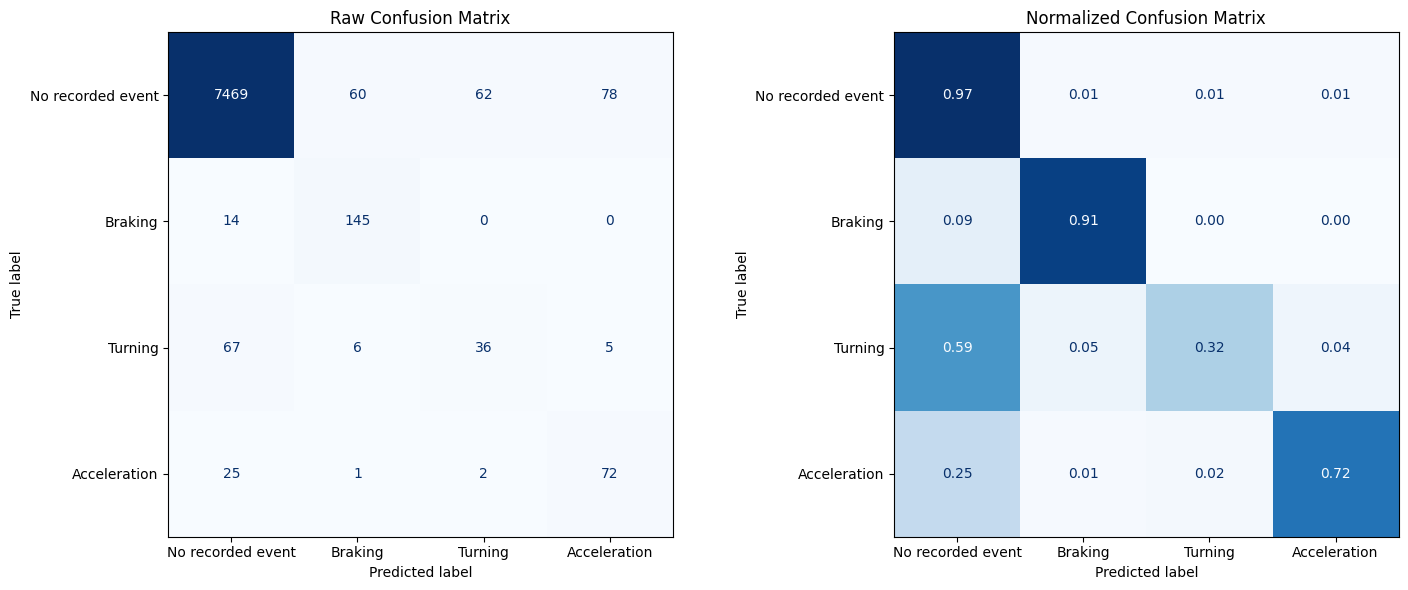


Final model saved.

CELL 8 COMPLETED SUCCESSFULLY
Selected Model: Tuned HGB
Test Macro F1: 0.6657
Test Accuracy: 0.9602
Test Balanced Accuracy: 0.7304
Dummy Macro F1: 0.2441

Artifacts saved in:
Results: /content/Driver-Behavior-and-Driving-Risk-Recognition/results
Plots: /content/Driver-Behavior-and-Driving-Risk-Recognition/plots
Models: /content/Driver-Behavior-and-Driving-Risk-Recognition/models

SVM configurations tested: 4

All Cell 8 experiments completed.


In [9]:

# ============================================================
# CELL 8: MODEL TUNING AND FINAL EVALUATION
# ============================================================

import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    GroupKFold,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    make_scorer
)

# ------------------------------------------------------------
# 0. CONFIGURATION
# ------------------------------------------------------------

SEED = 42

# Development: 4
# Final UAH experiment: 16
SVM_SEARCH_ITER = 4

N_FOLDS = 3
N_JOBS = 2

cv = GroupKFold(n_splits=N_FOLDS)

# Ensure output directories exist
for directory in [RESULTS_DIR, PLOTS_DIR, MODELS_DIR]:
    Path(directory).mkdir(parents=True, exist_ok=True)


def timed_run(name, function):

    print("\n" + "=" * 60)
    print("STARTING:", name)
    print("=" * 60)

    start = time.perf_counter()

    result = function()

    elapsed = time.perf_counter() - start

    print(f"\nCompleted {name}")
    print(f"Time: {elapsed / 60:.2f} minutes")

    return result


# ------------------------------------------------------------
# 1. FIXED-LABEL MACRO F1 SCORER
# ------------------------------------------------------------

MACRO_F1_SCORER = make_scorer(
    f1_score,
    labels=CLASS_LABELS,
    average="macro",
    zero_division=0
)


# ------------------------------------------------------------
# 2. MAJORITY CLASS BASELINE
# ------------------------------------------------------------

print("\n========== MAJORITY CLASS BASELINE ==========")

dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(X_dev, y_dev)

dummy_pred = dummy.predict(X_test)

dummy_macro_f1 = f1_score(
    y_test,
    dummy_pred,
    labels=CLASS_LABELS,
    average="macro",
    zero_division=0
)

dummy_accuracy = accuracy_score(
    y_test,
    dummy_pred
)

print("Dummy Macro F1:", round(dummy_macro_f1, 4))
print("Dummy Accuracy:", round(dummy_accuracy, 4))


# ------------------------------------------------------------
# 3. HGB HYPERPARAMETER TUNING
# ------------------------------------------------------------

print("\n========== HGB TUNING ==========")

hgb_pipeline = make_pipeline(
    HistGradientBoostingClassifier(
        random_state=SEED,
        early_stopping=False
    ),
    use_smote=use_smote,
    sampling_strategy=sampling_strategy
)

hgb_param_dist = {

    "model__learning_rate": [0.03, 0.05, 0.1],

    "model__max_iter": [100, 200, 300],

    "model__max_leaf_nodes": [7, 15, 31],

    "model__min_samples_leaf": [10, 20, 40],

    "model__l2_regularization": [0, 1, 5]
}

hgb_search = RandomizedSearchCV(

    estimator=hgb_pipeline,

    param_distributions=hgb_param_dist,

    n_iter=20,

    scoring=MACRO_F1_SCORER,

    cv=cv,

    random_state=SEED,

    n_jobs=N_JOBS,

    pre_dispatch=N_JOBS,

    refit=True,

    return_train_score=True,

    error_score="raise",

    verbose=1
)

hgb_search = timed_run(
    "HGB Hyperparameter Search",
    lambda: hgb_search.fit(
        X_dev,
        y_dev,
        groups=groups_dev
    )
)

print("\nBest HGB CV Macro F1:",
      round(hgb_search.best_score_, 4))

print("\nBest HGB Parameters:")
print(hgb_search.best_params_)


# ------------------------------------------------------------
# 4. RBF SVM PARAMETER SEARCH
# ------------------------------------------------------------

svm_param_dist = {

    "model__C": [0.1, 1, 10, 100],

    "model__gamma": [
        "scale",
        0.001,
        0.01,
        0.1
    ]
}


# ------------------------------------------------------------
# 5. WEIGHTED RBF SVM WITHOUT SMOTE
# ------------------------------------------------------------

print("\n========== WEIGHTED RBF SVM ==========")

svm_weighted_pipeline = make_pipeline(

    SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=SEED,
        cache_size=500,
        tol=1e-3
    ),

    use_smote=False
)

svm_weighted_search = RandomizedSearchCV(

    estimator=svm_weighted_pipeline,

    param_distributions=svm_param_dist,

    n_iter=SVM_SEARCH_ITER,

    scoring=MACRO_F1_SCORER,

    cv=cv,

    random_state=SEED,

    n_jobs=N_JOBS,

    pre_dispatch=N_JOBS,

    refit=True,

    return_train_score=True,

    error_score="raise",

    verbose=1
)

svm_weighted_search = timed_run(

    "Weighted RBF SVM Search",

    lambda: svm_weighted_search.fit(
        X_dev,
        y_dev,
        groups=groups_dev
    )
)

print(
    "\nWeighted RBF SVM Macro F1:",
    round(svm_weighted_search.best_score_, 4)
)

print(
    "Best parameters:",
    svm_weighted_search.best_params_
)


# ------------------------------------------------------------
# 6. RBF SVM WITH FULL SMOTE
# ------------------------------------------------------------

print("\n========== SMOTE RBF SVM ==========")

svm_smote_pipeline = make_pipeline(

    SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=SEED,
        cache_size=500,
        tol=1e-3
    ),

    use_smote=True,

    sampling_strategy="auto"

)

svm_smote_search = RandomizedSearchCV(

    estimator=svm_smote_pipeline,

    param_distributions=svm_param_dist,

    n_iter=SVM_SEARCH_ITER,

    scoring=MACRO_F1_SCORER,

    cv=cv,

    random_state=SEED,

    n_jobs=N_JOBS,

    pre_dispatch=N_JOBS,

    refit=True,

    return_train_score=True,

    error_score="raise",

    verbose=1
)

svm_smote_search = timed_run(

    "SMOTE RBF SVM Search",

    lambda: svm_smote_search.fit(
        X_dev,
        y_dev,
        groups=groups_dev
    )
)

print(
    "\nSMOTE RBF SVM Macro F1:",
    round(svm_smote_search.best_score_, 4)
)

print(
    "Best parameters:",
    svm_smote_search.best_params_
)


# ------------------------------------------------------------
# 7. LINEAR SVM BASELINE
# ------------------------------------------------------------

print("\n========== LINEAR SVM ==========")

linear_svm = make_pipeline(

    LinearSVC(
        class_weight="balanced",
        random_state=SEED,
        max_iter=5000
    ),

    use_smote=False
)

linear_scores = timed_run(

    "Linear SVM Cross Validation",

    lambda: cross_validate(

        linear_svm,

        X_dev,

        y_dev,

        groups=groups_dev,

        cv=cv,

        scoring=MACRO_F1_SCORER,

        n_jobs=N_JOBS,

        return_train_score=True

    )
)

linear_svm_score = linear_scores["test_score"].mean()

linear_svm_std = linear_scores["test_score"].std()

print("Linear SVM Macro F1:", round(linear_svm_score, 4))


# ------------------------------------------------------------
# 8. COMPARE MODELS USING DEVELOPMENT CV
# ------------------------------------------------------------

print("\n========== MODEL COMPARISON ==========")

model_comparison = pd.DataFrame([

    {
        "model": "Tuned HGB",

        "cv_macro_f1": hgb_search.best_score_
    },

    {
        "model": "Weighted RBF SVM",

        "cv_macro_f1": svm_weighted_search.best_score_
    },

    {
        "model": "SMOTE RBF SVM",

        "cv_macro_f1": svm_smote_search.best_score_
    },

    {
        "model": "Linear SVM",

        "cv_macro_f1": linear_svm_score
    }

]).sort_values(

    "cv_macro_f1",

    ascending=False

).reset_index(drop=True)


display(model_comparison)

model_comparison.to_csv(

    RESULTS_DIR / "model_comparison.csv",

    index=False

)


# ------------------------------------------------------------
# 9. SELECT BEST MODEL USING DEVELOPMENT CV ONLY
# ------------------------------------------------------------

candidate_estimators = {

    "Tuned HGB":
        hgb_search.best_estimator_,

    "Weighted RBF SVM":
        svm_weighted_search.best_estimator_,

    "SMOTE RBF SVM":
        svm_smote_search.best_estimator_,

    "Linear SVM":
        linear_svm

}

best_model_name = model_comparison.iloc[0]["model"]

final_pipeline = clone(
    candidate_estimators[best_model_name]
)

print("\nSelected model:", best_model_name)


# ------------------------------------------------------------
# 10. FIT FINAL MODEL ON DEVELOPMENT DATA
# ------------------------------------------------------------

print("\n========== FINAL MODEL TRAINING ==========")

final_pipeline = timed_run(

    "Final Model Training",

    lambda: final_pipeline.fit(
        X_dev,
        y_dev
    )
)


# ------------------------------------------------------------
# 11. FINAL UNTOUCHED TEST EVALUATION
# ------------------------------------------------------------

print("\n========== FINAL TEST EVALUATION ==========")

start_time = time.perf_counter()

y_pred = final_pipeline.predict(X_test)

end_time = time.perf_counter()

inference_seconds = end_time - start_time

macro_f1 = f1_score(

    y_test,

    y_pred,

    labels=CLASS_LABELS,

    average="macro",

    zero_division=0
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

balanced_acc = balanced_accuracy_score(
    y_test,
    y_pred
)

print("\nSelected Model:", best_model_name)

print(f"Macro F1: {macro_f1:.4f}")

print(f"Accuracy: {accuracy:.4f}")

print(f"Balanced Accuracy: {balanced_acc:.4f}")

print(f"Inference Time: {inference_seconds:.4f} seconds")

print(
    "Inference per window:",
    inference_seconds / len(X_test)
)


# ------------------------------------------------------------
# 12. SAVE FINAL TEST METRICS
# ------------------------------------------------------------

test_metrics = {

    "model": best_model_name,

    "macro_f1": macro_f1,

    "accuracy": accuracy,

    "balanced_accuracy": balanced_acc,

    "dummy_macro_f1": dummy_macro_f1,

    "inference_seconds": inference_seconds,

    "inference_seconds_per_window":
        inference_seconds / len(X_test),

    "test_windows": len(X_test),

    "test_trips": groups_test.nunique()

}

pd.DataFrame([test_metrics]).to_csv(

    RESULTS_DIR / "final_test_metrics.csv",

    index=False

)


# ------------------------------------------------------------
# 13. CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n========== CLASSIFICATION REPORT ==========")

report = classification_report(

    y_test,

    y_pred,

    labels=CLASS_LABELS,

    target_names=LABEL_NAMES,

    output_dict=True,

    zero_division=0

)

print(

    classification_report(

        y_test,

        y_pred,

        labels=CLASS_LABELS,

        target_names=LABEL_NAMES,

        zero_division=0

    )

)

with open(

    RESULTS_DIR / "test_classification_report.json",

    "w"

) as f:

    json.dump(report, f, indent=4)


# ------------------------------------------------------------
# 14. RAW AND NORMALIZED CONFUSION MATRICES
# ------------------------------------------------------------

cm = confusion_matrix(

    y_test,

    y_pred,

    labels=CLASS_LABELS

)

cm_normalized = confusion_matrix(

    y_test,

    y_pred,

    labels=CLASS_LABELS,

    normalize="true"

)

fig, axes = plt.subplots(

    1,

    2,

    figsize=(15, 6)

)

ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=LABEL_NAMES

).plot(

    ax=axes[0],

    cmap="Blues",

    values_format="d",

    colorbar=False

)

axes[0].set_title("Raw Confusion Matrix")

ConfusionMatrixDisplay(

    confusion_matrix=cm_normalized,

    display_labels=LABEL_NAMES

).plot(

    ax=axes[1],

    cmap="Blues",

    values_format=".2f",

    colorbar=False

)

axes[1].set_title("Normalized Confusion Matrix")

plt.tight_layout()

plt.savefig(

    PLOTS_DIR / "confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)

plt.savefig(

    PLOTS_DIR / "normalized_confusion_matrix.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()


# ------------------------------------------------------------
# 15. SAVE FINAL MODEL
# ------------------------------------------------------------

joblib.dump(

    final_pipeline,

    MODELS_DIR / "final_event_classifier.joblib"

)

print("\nFinal model saved.")


# ------------------------------------------------------------
# 16. SAVE HYPERPARAMETER RESULTS
# ------------------------------------------------------------

search_results = {

    "hgb_best_params": hgb_search.best_params_,

    "hgb_best_cv_macro_f1":
        float(hgb_search.best_score_),

    "weighted_svm_best_params":
        svm_weighted_search.best_params_,

    "weighted_svm_cv_macro_f1":
        float(svm_weighted_search.best_score_),

    "smote_svm_best_params":
        svm_smote_search.best_params_,

    "smote_svm_cv_macro_f1":
        float(svm_smote_search.best_score_),

    "linear_svm_cv_macro_f1":
        float(linear_svm_score),

    "svm_search_iterations":
        SVM_SEARCH_ITER

}

with open(

    RESULTS_DIR / "hyperparameter_tuning.json",

    "w"

) as f:

    json.dump(search_results, f, indent=4)


# ------------------------------------------------------------
# 17. SAVE ALL SEARCH CONFIGURATIONS
# ------------------------------------------------------------

search_frames = [

    pd.DataFrame(
        hgb_search.cv_results_
    ).assign(
        experiment="HGB"
    ),

    pd.DataFrame(
        svm_weighted_search.cv_results_
    ).assign(
        experiment="Weighted RBF SVM"
    ),

    pd.DataFrame(
        svm_smote_search.cv_results_
    ).assign(
        experiment="SMOTE RBF SVM"
    )

]

all_search_results = pd.concat(

    search_frames,

    ignore_index=True

)

all_search_results.to_csv(

    RESULTS_DIR / "hyperparameter_tuning.csv",

    index=False

)


# ------------------------------------------------------------
# 18. SAVE SEARCH OBJECTS FOR REUSE
# ------------------------------------------------------------

joblib.dump(
    hgb_search,
    MODELS_DIR / "hgb_search.joblib"
)

joblib.dump(
    svm_weighted_search,
    MODELS_DIR / "weighted_svm_search.joblib"
)

joblib.dump(
    svm_smote_search,
    MODELS_DIR / "smote_svm_search.joblib"
)


# ------------------------------------------------------------
# 19. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)

print("CELL 8 COMPLETED SUCCESSFULLY")

print("=" * 60)

print("Selected Model:", best_model_name)

print("Test Macro F1:", round(macro_f1, 4))

print("Test Accuracy:", round(accuracy, 4))

print("Test Balanced Accuracy:", round(balanced_acc, 4))

print("Dummy Macro F1:", round(dummy_macro_f1, 4))

print("\nArtifacts saved in:")

print("Results:", RESULTS_DIR)

print("Plots:", PLOTS_DIR)

print("Models:", MODELS_DIR)

print("\nSVM configurations tested:", SVM_SEARCH_ITER)

print("\nAll Cell 8 experiments completed.")


In [10]:
# CELL 9: Nested Leave-One-Driver-Out Evaluation

from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier

nested_lodo_results = []

drivers = sorted(df["driver"].astype(str).unique())

print("========== NESTED LODO EVALUATION ==========")

param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [100, 200, 300],
    "model__max_leaf_nodes": [7, 15, 31],
    "model__min_samples_leaf": [10, 20, 40],
    "model__l2_regularization": [0, 1, 5]
}

for held_out_driver in drivers:

    print(f"\nHolding out driver: {held_out_driver}")

    # --------------------------------------------
    # 1. Outer split
    # --------------------------------------------

    train_mask = (
        df["driver"].astype(str) != held_out_driver
    )

    test_mask = (
        df["driver"].astype(str) == held_out_driver
    )

    X_outer_train = X.loc[train_mask]
    y_outer_train = y.loc[train_mask]

    X_outer_test = X.loc[test_mask]
    y_outer_test = y.loc[test_mask]

    driver_outer_train = (
        df.loc[train_mask, "driver"].astype(str)
    )

    if X_outer_test.empty:
        continue

    # --------------------------------------------
    # 2. Inner driver-grouped validation
    # --------------------------------------------

    n_inner = min(
        3,
        driver_outer_train.nunique()
    )

    inner_cv = GroupKFold(
        n_splits=n_inner
    )

    inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=driver_outer_train
        )
    )

    # Verify no driver overlap in any inner fold
    for inner_train_idx, inner_val_idx in inner_splits:

        inner_train_drivers = set(
            driver_outer_train.iloc[inner_train_idx]
        )

        inner_val_drivers = set(
            driver_outer_train.iloc[inner_val_idx]
        )

        assert inner_train_drivers.isdisjoint(
            inner_val_drivers
        )

    # --------------------------------------------
    # 3. Check SMOTE feasibility
    # --------------------------------------------

    smote_feasible = True

    for inner_train_idx, _ in inner_splits:

        counts = (
            y_outer_train.iloc[inner_train_idx]
            .value_counts()
            .reindex(CLASS_LABELS, fill_value=0)
        )

        if counts.min() < 4:
            smote_feasible = False
            break

    strategies = ["none"]

    if smote_feasible:
        strategies.extend([
            "partial_smote",
            "full_smote"
        ])

    else:
        print(
            "SMOTE skipped: insufficient class samples "
            "in at least one inner training fold."
        )

    # --------------------------------------------
    # 4. Compare strategies inside outer training
    # --------------------------------------------

    driver_strategy_results = []

    for strategy in strategies:

        print("Testing strategy:", strategy)

        if strategy == "none":

            use_smote_inner = False
            sampling_inner = "auto"

        elif strategy == "partial_smote":

            use_smote_inner = True
            sampling_inner = partial_smote_strategy

        else:

            use_smote_inner = True
            sampling_inner = "auto"

        inner_pipeline = make_pipeline(
            HistGradientBoostingClassifier(
                random_state=SEED,
                early_stopping=False
            ),
            use_smote=use_smote_inner,
            sampling_strategy=sampling_inner
        )

        inner_search = RandomizedSearchCV(
            estimator=inner_pipeline,
            param_distributions=param_dist,
            n_iter=4,
            scoring=MACRO_F1_SCORER,
            cv=inner_splits,
            random_state=SEED,
            n_jobs=1,
            refit=True,
            error_score="raise"
        )

        inner_search.fit(
            X_outer_train,
            y_outer_train
        )

        driver_strategy_results.append({
            "strategy": strategy,
            "score": inner_search.best_score_,
            "search": inner_search
        })

    # --------------------------------------------
    # 5. Select best inner strategy
    # --------------------------------------------

    best_inner = max(
        driver_strategy_results,
        key=lambda x: x["score"]
    )

    best_inner_search = best_inner["search"]

    selected_strategy = best_inner["strategy"]

    # --------------------------------------------
    # 6. Predict held-out driver
    # --------------------------------------------

    y_outer_pred = best_inner_search.best_estimator_.predict(
        X_outer_test
    )

    # --------------------------------------------
    # 7. Outer evaluation
    # --------------------------------------------

    outer_macro_f1 = f1_score(
        y_outer_test,
        y_outer_pred,
        labels=CLASS_LABELS,
        average="macro",
        zero_division=0
    )

    outer_balanced_accuracy = balanced_accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    outer_accuracy = accuracy_score(
        y_outer_test,
        y_outer_pred
    )

    print("Selected strategy:", selected_strategy)
    print("Inner CV Macro F1:", best_inner["score"])
    print("Outer Macro F1:", outer_macro_f1)
    print("Outer Balanced Accuracy:", outer_balanced_accuracy)
    print("Outer Accuracy:", outer_accuracy)

    # --------------------------------------------
    # 8. Save driver results
    # --------------------------------------------

    nested_lodo_results.append({
        "held_out_driver": held_out_driver,
        "selected_strategy": selected_strategy,
        "inner_cv_macro_f1": best_inner["score"],
        "outer_macro_f1": outer_macro_f1,
        "outer_balanced_accuracy": outer_balanced_accuracy,
        "outer_accuracy": outer_accuracy,
        "test_windows": len(y_outer_test),
        "test_class_counts": json.dumps(
            y_outer_test.value_counts().to_dict()
        ),
        "best_params": json.dumps(
            best_inner_search.best_params_
        )
    })

# --------------------------------------------
# 9. Summarize all outer folds
# --------------------------------------------

lodo_df = pd.DataFrame(
    nested_lodo_results
)

display(lodo_df)

print("\n========== NESTED LODO SUMMARY ==========")

print(
    "Mean Macro F1:",
    lodo_df["outer_macro_f1"].mean()
)

print(
    "Standard Deviation:",
    lodo_df["outer_macro_f1"].std()
)

print(
    "Mean Balanced Accuracy:",
    lodo_df["outer_balanced_accuracy"].mean()
)

lodo_df.to_csv(
    RESULTS_DIR / "nested_lodo_results.csv",
    index=False
)

print("\nNested LODO results saved.")

========== NESTED LODO EVALUATION ==========

Holding out driver: D1
Testing strategy: none
Testing strategy: partial_smote
Testing strategy: full_smote


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Selected strategy: full_smote
Inner CV Macro F1: 0.6561207408706499
Outer Macro F1: 0.5066981883355854
Outer Balanced Accuracy: 0.7219012543184188
Outer Accuracy: 0.9792831986741247

Holding out driver: D2
Testing strategy: none
Testing strategy: partial_smote
Testing strategy: full_smote
Selected strategy: full_smote
Inner CV Macro F1: 0.6394364226398606
Outer Macro F1: 0.6694534199917147
Outer Balanced Accuracy: 0.7565578206038293
Outer Accuracy: 0.9622322435174746

Holding out driver: D3
Testing strategy: none
Testing strategy: partial_smote
Testing strategy: full_smote
Selected strategy: full_smote
Inner CV Macro F1: 0.635969574012276
Outer Macro F1: 0.6897595518210011
Outer Balanced Accuracy: 0.7552671107628004
Outer Accuracy: 0.9741141912979622

Holding out driver: D4
Testing strategy: none
Testing strategy: partial_smote
Testing strategy: full_smote
Selected strategy: full_smote
Inner CV Macro F1: 0.6412035371778376
Outer Macro F1: 0.6865560220397433
Outer Balanced Accuracy: 0.7

,held_out_driver,selected_strategy,inner_cv_macro_f1,outer_macro_f1,outer_balanced_accuracy,outer_accuracy,test_windows,test_class_counts,best_params
0,D1,full_smote,0.656121,0.506698,0.721901,0.979283,4827,"{""0"": 4717, ""1"": 68, ""2"": 42}","{""model__min_samples_leaf"": 20, ""model__max_le..."
1,D2,full_smote,0.639436,0.669453,0.756558,0.962232,5322,"{""0"": 5111, ""1"": 87, ""3"": 82, ""2"": 42}","{""model__min_samples_leaf"": 40, ""model__max_le..."
2,D3,full_smote,0.635970,0.689760,0.755267,0.974114,5447,"{""0"": 5280, ""1"": 114, ""2"": 29, ""3"": 24}","{""model__min_samples_leaf"": 40, ""model__max_le..."
3,D4,full_smote,0.641204,0.686556,0.792335,0.976094,5689,"{""0"": 5536, ""1"": 67, ""3"": 66, ""2"": 20}","{""model__min_samples_leaf"": 40, ""model__max_le..."
4,D5,full_smote,0.653946,0.613165,0.663794,0.955669,5301,"{""0"": 5072, ""1"": 98, ""3"": 73, ""2"": 58}","{""model__min_samples_leaf"": 20, ""model__max_le..."
5,D6,partial_smote,0.663538,0.627235,0.634269,0.930409,4469,"{""0"": 4144, ""2"": 175, ""1"": 86, ""3"": 64}","{""model__min_samples_leaf"": 10, ""model__max_le..."



========== NESTED LODO SUMMARY ==========
Mean Macro F1: 0.6321444860830145
Standard Deviation: 0.06898286003588412
Mean Balanced Accuracy: 0.7206873282606884

Nested LODO results saved.


In [11]:
# CELL 10: Final Experiment Summary and Artifact Verification

print("=" * 65)
print("       UAH DRIVESET - FINAL EXPERIMENT SUMMARY")
print("=" * 65)

# -------------------------------------------------
# 1. Display experiment results
# -------------------------------------------------

files_to_display = [
    "imbalance_comparison.csv",
    "model_comparison.csv",
    "final_test_metrics.csv",
    "nested_lodo_results.csv",
    "hyperparameter_tuning.csv"
]

for filename in files_to_display:

    path = RESULTS_DIR / filename

    if path.exists():

        print("\n", filename)

        result = pd.read_csv(path)

        display(result.head(10))

    else:

        print("Missing:", filename)

# -------------------------------------------------
# 2. Check saved model
# -------------------------------------------------

print("\n========== SAVED MODELS ==========")

for model_file in MODELS_DIR.glob("*.joblib"):
    print(model_file.name)

# -------------------------------------------------
# 3. Check generated plots
# -------------------------------------------------

print("\n========== GENERATED PLOTS ==========")

for plot_file in PLOTS_DIR.glob("*.png"):
    print(plot_file.name)

# -------------------------------------------------
# 4. Verify required artifacts
# -------------------------------------------------

required_artifacts = [
    RESULTS_DIR / "imbalance_comparison.csv",
    RESULTS_DIR / "model_comparison.csv",
    RESULTS_DIR / "final_test_metrics.csv",
    RESULTS_DIR / "test_classification_report.json",
    RESULTS_DIR / "nested_lodo_results.csv",
    RESULTS_DIR / "hyperparameter_tuning.csv",
    RESULTS_DIR / "hyperparameter_tuning.json",
    RESULTS_DIR / "fold_class_audit.json",
    PLOTS_DIR / "confusion_matrix.png",
    PLOTS_DIR / "normalized_confusion_matrix.png",
    MODELS_DIR / "final_event_classifier.joblib"
]

print("\n========== ARTIFACT AUDIT ==========")

all_present = True

for artifact in required_artifacts:

    exists = (
        artifact.exists()
        and artifact.stat().st_size > 0
    )

    print(
        f"[{'PASS' if exists else 'FAIL'}] {artifact}"
    )

    if not exists:
        all_present = False

if all_present:

    print("\nAll required artifacts are present.")

else:

    print("\nSome artifacts are missing.")

# -------------------------------------------------
# 5. Document evaluation limitations
# -------------------------------------------------

limitations = {
    "active_flag_verified": ACTIVE_VERIFIED,
    "raw_signal_jerk_available": False,
    "exact_raw_signal_rms_available": False,
    "window_length_ablation_completed": False,
    "event_level_evaluation_completed": False,
    "feature_extraction_time_measured": False,
    "model_inference_time_measured": True,
    "road_transfer_evaluation_completed": False
}

with open(
    RESULTS_DIR / "evaluation_limitations.json",
    "w"
) as f:

    json.dump(limitations, f, indent=4)

print("\n========== LIMITATIONS ==========")

for name, status in limitations.items():
    print(name, ":", status)

print("\nFinal experiment summary completed.")
print("=" * 65)

       UAH DRIVESET - FINAL EXPERIMENT SUMMARY

 imbalance_comparison.csv


,experiment,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,train_macro_f1_mean
0,HGB - Partial SMOTE,0.636142,0.019390,0.643199,1.0
1,HGB - Full SMOTE,0.630373,0.018819,0.673517,1.0
2,HGB - No resampling,0.561607,0.011378,0.522965,1.0
3,RF - Class weighting,0.440714,0.022814,0.397770,1.0



 model_comparison.csv


,model,cv_macro_f1
0,Tuned HGB,0.644806
1,Linear SVM,0.566418
2,Weighted RBF SVM,0.492762
3,SMOTE RBF SVM,0.482363



 final_test_metrics.csv


,model,macro_f1,accuracy,balanced_accuracy,dummy_macro_f1,inference_seconds,inference_seconds_per_window,test_windows,test_trips
0,Tuned HGB,0.665688,0.960209,0.730415,0.244065,0.560278,0.00007,8042,10



 nested_lodo_results.csv


,held_out_driver,selected_strategy,inner_cv_macro_f1,outer_macro_f1,outer_balanced_accuracy,outer_accuracy,test_windows,test_class_counts,best_params
0,D1,full_smote,0.656121,0.506698,0.721901,0.979283,4827,"{""0"": 4717, ""1"": 68, ""2"": 42}","{""model__min_samples_leaf"": 20, ""model__max_le..."
1,D2,full_smote,0.639436,0.669453,0.756558,0.962232,5322,"{""0"": 5111, ""1"": 87, ""3"": 82, ""2"": 42}","{""model__min_samples_leaf"": 40, ""model__max_le..."
2,D3,full_smote,0.635970,0.689760,0.755267,0.974114,5447,"{""0"": 5280, ""1"": 114, ""2"": 29, ""3"": 24}","{""model__min_samples_leaf"": 40, ""model__max_le..."
3,D4,full_smote,0.641204,0.686556,0.792335,0.976094,5689,"{""0"": 5536, ""1"": 67, ""3"": 66, ""2"": 20}","{""model__min_samples_leaf"": 40, ""model__max_le..."
4,D5,full_smote,0.653946,0.613165,0.663794,0.955669,5301,"{""0"": 5072, ""1"": 98, ""3"": 73, ""2"": 58}","{""model__min_samples_leaf"": 20, ""model__max_le..."
5,D6,partial_smote,0.663538,0.627235,0.634269,0.930409,4469,"{""0"": 4144, ""2"": 175, ""1"": 86, ""3"": 64}","{""model__min_samples_leaf"": 10, ""model__max_le..."



 hyperparameter_tuning.csv


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__min_samples_leaf,param_model__max_leaf_nodes,param_model__max_iter,param_model__learning_rate,param_model__l2_regularization,params,...,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score,experiment,param_model__gamma,param_model__C
0,16.159748,0.117103,1.324258,0.209583,10.0,31.0,300.0,0.03,0.0,"{'model__min_samples_leaf': 10, 'model__max_le...",...,0.030259,10,1.000000,1.000000,1.000000,1.000000,0.000000,HGB,NaN,NaN
1,5.297537,0.386713,0.301387,0.016636,10.0,31.0,100.0,0.03,0.0,"{'model__min_samples_leaf': 10, 'model__max_le...",...,0.027325,11,0.878715,0.882779,0.877255,0.879583,0.002337,HGB,NaN,NaN
2,10.904908,0.015828,0.663587,0.016863,40.0,31.0,200.0,0.10,1.0,"{'model__min_samples_leaf': 40, 'model__max_le...",...,0.014025,1,1.000000,1.000000,1.000000,1.000000,0.000000,HGB,NaN,NaN
3,10.727360,0.300895,0.829930,0.131058,20.0,31.0,200.0,0.10,5.0,"{'model__min_samples_leaf': 20, 'model__max_le...",...,0.013411,3,1.000000,1.000000,1.000000,1.000000,0.000000,HGB,NaN,NaN
4,11.100107,0.111285,0.844147,0.063548,20.0,15.0,300.0,0.10,5.0,"{'model__min_samples_leaf': 20, 'model__max_le...",...,0.006568,6,1.000000,1.000000,1.000000,1.000000,0.000000,HGB,NaN,NaN
5,7.106841,0.299312,0.633885,0.073428,20.0,15.0,200.0,0.03,5.0,"{'model__min_samples_leaf': 20, 'model__max_le...",...,0.016362,4,0.828183,0.839795,0.839913,0.835964,0.005502,HGB,NaN,NaN
6,15.772213,0.530159,0.974789,0.061896,40.0,31.0,300.0,0.05,5.0,"{'model__min_samples_leaf': 40, 'model__max_le...",...,0.013087,5,1.000000,1.000000,1.000000,1.000000,0.000000,HGB,NaN,NaN
7,11.170183,0.156893,0.647188,0.027433,10.0,31.0,200.0,0.10,1.0,"{'model__min_samples_leaf': 10, 'model__max_le...",...,0.021026,8,1.000000,1.000000,1.000000,1.000000,0.000000,HGB,NaN,NaN
8,4.963625,0.299141,0.447539,0.009133,10.0,7.0,200.0,0.03,0.0,"{'model__min_samples_leaf': 10, 'model__max_le...",...,0.023305,18,0.725542,0.724519,0.724657,0.724906,0.000453,HGB,NaN,NaN
9,3.879513,0.254955,0.275216,0.007375,40.0,15.0,100.0,0.05,1.0,"{'model__min_samples_leaf': 40, 'model__max_le...",...,0.023943,15,0.824072,0.829124,0.824295,0.825830,0.002330,HGB,NaN,NaN



========== SAVED MODELS ==========
smote_svm_search.joblib
hgb_search.joblib
final_event_classifier.joblib
weighted_svm_search.joblib

========== GENERATED PLOTS ==========
05_speed_histogram.png
normalized_confusion_matrix.png
03_signals_with_events.png
06_correlation_heatmap.png
confusion_matrix.png
01_trips_per_behavior.png
07_events_by_behavior.png
02_class_imbalance.png
04_feature_boxplots.png

========== ARTIFACT AUDIT ==========
[PASS] /content/Driver-Behavior-and-Driving-Risk-Recognition/results/imbalance_comparison.csv
[PASS] /content/Driver-Behavior-and-Driving-Risk-Recognition/results/model_comparison.csv
[PASS] /content/Driver-Behavior-and-Driving-Risk-Recognition/results/final_test_metrics.csv
[PASS] /content/Driver-Behavior-and-Driving-Risk-Recognition/results/test_classification_report.json
[PASS] /content/Driver-Behavior-and-Driving-Risk-Recognition/results/nested_lodo_results.csv
[PASS] /content/Driver-Behavior-and-Driving-Risk-Recognition/results/hyperparameter_tunin